# A / B Test
för andelar (binär data)

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [29]:
df = pd.read_csv('../files/simulated_data.csv', parse_dates=['date'])
display(df.head())
df.info()
df.select_dtypes(include='number').describe()

,group,outcome,date
0,A,0,2026-10-01
1,A,1,2026-10-01
2,A,0,2026-10-01
3,A,0,2026-10-01
4,A,0,2026-10-01


<class 'pandas.DataFrame'>
RangeIndex: 312 entries, 0 to 311
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   group    312 non-null    str           
 1   outcome  312 non-null    int64         
 2   date     312 non-null    datetime64[us]
dtypes: datetime64[us](1), int64(1), str(1)
memory usage: 7.4 KB


,outcome
count,312.000000
mean,0.288462
std,0.453775
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,1.000000


In [30]:
summary = df.groupby('group')['outcome'].agg(
    observations='count',
    successes='sum',
    proportion='mean'
).reset_index()

# 95 % CI
z = stats.norm.ppf(0.975) # 0.975 är +- 1.96 * osäkerhet
ci_low, ci_high = [], []

for _, row in summary.iterrows():
    n = row['observations']
    p = row['proportion']
    se = np.sqrt(p*(1-p)/n)
    ci_low.append(p - z * se)
    ci_high.append(p + z * se)

# konfidensintervallet är för andel
summary['ci_low'] = ci_low
summary['ci_high'] = ci_high
summary


,group,observations,successes,proportion,ci_low,ci_high
0,A,175,42,0.240000,0.176724,0.303276
1,B,137,48,0.350365,0.270477,0.430253


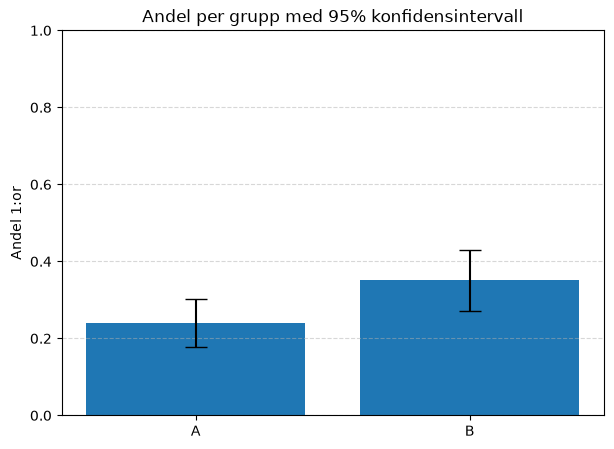

In [31]:
fig, ax =plt.subplots(figsize=(7,5))
x = np.arange(len(summary))
ax.bar(x, summary['proportion'], yerr=[summary['proportion']- summary['ci_low'], 
summary['ci_high'] - summary['proportion']], capsize = 8
)

ax.set_xticks(x)
ax.set_xticklabels(summary['group'])
ax.set_ylim(0,1)
ax.set_ylabel('Andel 1:or')
ax.set_title('Andel per grupp med 95% konfidensintervall')
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()


- H0 (nollhypotes): Det finns ingen verklig skillnad i andel mellan B och A i populationen
- H1 (tvåsidig mothypotes): Det finns en skillnad (okänt om B är större än A eller A är större än B)
- H1 (ensidig, bestäms i förväg): B har högre andel än A. (bör undvikas för det mesta)

In [32]:
n_A = int(summary.loc[summary['group'] == 'A', 'observations'].values[0]) # antal obesrvationer i grupp A
n_B = int(summary.loc[summary['group'] == 'B', 'observations'].values[0])
x_A = int(summary.loc[summary['group'] == 'A', 'successes'].values[0])  # antal 1 i grupp A
x_B = int(summary.loc[summary['group'] == 'B', 'successes'].values[0])

p_A = x_A / n_A # räknar andelar
p_B = x_B / n_B
diff = p_B - p_A # diff mellan andelarna

p_pooled = (x_A + x_B ) / (n_A + n_B) # andelar av helheten både grupp A och B
se_pooled = np.sqrt(p_pooled * (1 - p_pooled) * (1 / n_A + 1 / n_B)) # standardfel

z_stat = diff / se_pooled

p_two_sided = 2 * (1 - stats.norm.cdf(abs(z_stat)))
p_one_sided_B_greater = 1 - stats.norm.cdf(z_stat)

print('Z-testets teststatistika, det standardiserade måttet på skillnaden mellan andelarna:', z_stat)
print('P-värdet för tvåsidigt z-test, probability:', p_two_sided)
print('P-värdet för ensidigt z-test:', p_one_sided_B_greater)
print('diff:', diff)

Z-testets teststatistika, det standardiserade måttet på skillnaden mellan andelarna: 2.135453342617615
P-värdet för tvåsidigt z-test, probability: 0.03272399744817189
P-värdet för ensidigt z-test: 0.016361998724085947
diff: 0.11036496350364966


1. Skillnaden mellan grupperna (diff) +0,1104 Det motsvarar 11,04 procentenheter.
2. Z-testets teststatistika 2,1355 Det betyder att den observerade skillnaden ligger cirka 2,14 standardfel från den skillnad på noll som förväntas enligt nollhypotesen.
3. P-värdet för tvåsidigt test 0,03272 Det innebär att om nollhypotesen är sann, är sannolikheten cirka 3,27 % att få en skillnad som är minst lika extrem som den observerade, i någon riktning. Det betyder att vi **förkastar** nollhypotesen på 5 % signifikansnivå.

Det fanns en statistiskt signifikant skillnad i andelen positiva utfall mellan grupperna. Grupp B hade en högre andel positiva utfall (35,04 %) jämfört med grupp A (24,00 %), vilket motsvarar en skillnad på 11,04 procentenheter. Ett tvåsidigt z-test för skillnad mellan två andelar visade att skillnaden var statistiskt signifikant (z = 2,14, p = 0,0327).

En statistisk reservation: Detta bygger på normalapproximationen och ett poolat standardfel under nollhypotesen. Testet förutsätter oberoende observationer och tillräckligt stora förväntade antal i respektive utfallskategori. Dina gruppstorlekar och andelar uppfyller dessa villkor.
Statistisk signifikans innebär inte automatiskt att skillnaden är praktiskt betydelsefull eller att gruppindelningen orsakar skillnaden.

In [33]:
se = np.sqrt(p_A * (1 - p_A) / n_A + p_B * (1-p_B) / n_B)
z_crit = stats.norm.ppf(0.975)
ci_low = diff - z_crit * se
ci_high = diff + z_crit * se
print([ci_low, ci_high], diff)

[np.float64(0.008453095686323714), np.float64(0.2122768313209756)] 0.11036496350364966


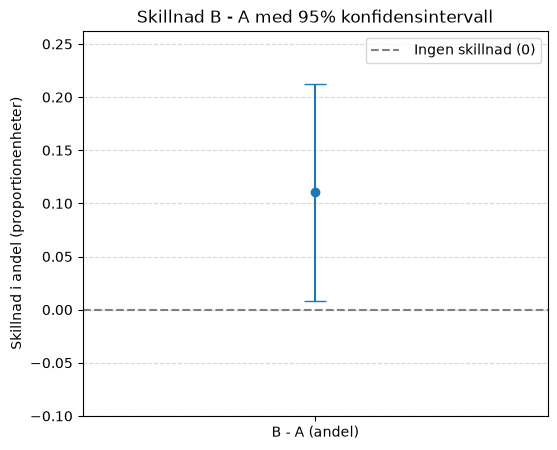

In [35]:
fig, ax = plt.subplots(figsize=(6,5))
ax.errorbar([0], [diff], yerr = [[diff - ci_low], [ci_high - diff]], fmt='o', capsize=8)
ax.axhline(0, linestyle='--', color='grey', label=' Ingen skillnad (0)')
ax.set_xticks([0])
ax.set_xticklabels(['B - A (andel)'])
ax.set_ylim(min(-0.1, ci_low - 0.05), max(0.1, ci_high + 0.05))
ax.set_ylabel('Skillnad i andel (proportionenheter)')
ax.set_title('Skillnad B - A med 95% konfidensintervall')
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

In [37]:
absolute_pp = diff * 100
relative_lift = (p_B / p_A - 1) * 100 if p_A > 0 else np.inf
absolute_pp, relative_lift

(11.036496350364967, 45.98540145985404)

absolut diff i procentenheter 11 %
relativ effektstorlek = 46 %

# A/B-test för andelar
Ett A/B-test jämför två varianter för att undersöka om de ger olika resultat. När utfallet endast har två möjliga värden, exempelvis köp eller inget köp, arbetar vi med andelar.  
I den här lektionen följer vi ett fullständigt analysflöde: data kontrolleras och sammanfattas, gruppernas andelar jämförs och skillnaden analyseras med konfidensintervall och ett z-test.

#### Binära utfall och andelar
Ett binärt utfall har två möjliga värden. Det kan kodas som:
- 1 för ett positivt utfall
- 0 för ett negativt utfall

Exempel på binära utfall är:
- klickade eller klickade inte
- genomförde ett köp eller genomförde inget köp
- svarade ja eller svarade nej
- tillfrisknade eller tillfrisknade inte  

När observationerna är kodade med noll och ett är medelvärdet samma sak som andelen ettor.
Om en grupp innehåller 100 personer och 28 av dem genomför ett köp blir medelvärdet:
28 / 100 = 0,28
Andelen genomförda köp är alltså 0,28 eller 28%

#### Kontrollera data före analysen
Innan grupperna jämförs behöver vi kontrollera att datan motsvarar experimentets upplägg.
För ett binärt utfall bör vi bland annat undersöka:
- att varje observation tillhör rätt grupp
- att utfallen endast innehåller de tillåtna värdena noll och ett
- om det finns saknade värden
- om det finns dubbletter
- om samma person förekommer flera gånger när observationerna ska vara oberoende
-om grupperna skapades genom den avsedda slumpmässiga fördelningen

Det räcker inte att koden kan genomföra testet. Resultatet blir endast meningsfullt om datan och experimentets design är rimliga.

## Absolut och relativ skillnad
Låt andelen i grupp A betecknas med pA och andelen i grupp B med pB.  
Den absoluta skillnaden beräknas som:  
**skillnad = pB − pA**  
Om andelarna skrivs i procent uttrycks den absoluta skillnaden i procentenheter.  
Den relativa förändringen beräknas i förhållande till grupp A:  
**relativ förändring = (pB / pA − 1) × 100**  
Den absoluta och relativa förändringen svarar på olika frågor:  
- Procentenheter: Hur mycket större eller mindre är andelen?
- Relativ förändring: Hur stor är förändringen i förhållande till utgångsläget?  

Båda måtten kan vara användbara, men det måste framgå vilket som redovisas. Den relativa förändringen kan dessutom bli missvisande när andelen i grupp A är mycket liten.

## Hypoteser för två andelar
Vid ett tvåsidigt test kan hypoteserna skrivas:  
**Nollhypotes, H₀: pB − pA = 0**  
**Alternativhypotes, H₁: pB − pA ≠ 0**  
Nollhypotesen säger att grupperna har samma andel i populationen. Den observerade skillnaden i stickprovet förklaras då av slumpmässig variation.  
Det tvåsidiga alternativet säger att andelarna skiljer sig, utan att i förväg bestämma vilken grupp som har den högre andelen.  
Om frågeställningen och riktningen har bestämts innan data analyseras kan ett ensidigt alternativ ibland användas, exempelvis:  
**H₁: pB > pA**
Riktningen får inte väljas i efterhand efter att vi har sett vilken grupp som fick bäst resultat.

## Z-test för två andelar
Ett z-test jämför den observerade skillnaden med hur mycket skillnaden förväntas variera om nollhypotesen gäller.  
Grundidén är:  
**z = observerad skillnad / skillnadens standardfel**  
Ett z-värde nära noll innebär att skillnaden är liten i förhållande till osäkerheten. Ett z-värde långt från noll innebär att den observerade skillnaden är stor i förhållande till den variation som förväntas av slumpen.  
När standardfelet för hypotesprovet beräknas används en **poolad andel**. Observationerna från båda grupperna används då för att uppskatta en gemensam andel.  
Det görs eftersom nollhypotesen utgår från att grupperna har samma andel i populationen. Om nollhypotesen gäller är den gemensamma andelen den relevanta utgångspunkten för att beräkna den förväntade slumpvariationen.  
Z-värdet används sedan för att beräkna ett p-värde.

## Konfidensintervall för skillnaden
P-värdet undersöker hur förenligt resultatet är med nollhypotesen. Konfidensintervallet beskriver i stället vilka storlekar på skillnaden som är rimliga utifrån data.  
För konfidensintervallet används gruppernas observerade andelar var för sig när standardfelet beräknas. Detta kallas ibland ett **opoolat standardfel**.  
Intervallet byggs runt den observerade skillnaden:  
**observerad skillnad ± kritiskt värde × standardfel**  
För ett ungefärligt 95-procentigt intervall används det kritiska värdet 1,96.  
- Om intervallet innehåller noll är en population utan skillnad förenlig med data.
- Om hela intervallet ligger över noll talar resultatet för att andelen i B är högre.
- Om hela intervallet ligger under noll talar resultatet för att andelen i B är lägre.
- Intervallets bredd visar hur osäker skattningen är.  

Vi bör analysera konfidensintervallet för **själva skillnaden**. Att endast titta på om gruppernas separata konfidensintervall överlappar är inte ett tillförlitligt hypotesprov.

## När fungerar normalapproximationen?
Z-testet och intervallet som användes i lektionsvideon bygger på en normalapproximation. Den fungerar bäst när båda grupperna innehåller tillräckligt många positiva och negativa utfall.  
En vanlig tumregel är att varje grupp bör ha åtminstone ungefär 5–10 förväntade observationer av varje utfall. Det räcker alltså inte alltid att en grupp totalt innehåller många observationer.  
Om utfallet är mycket ovanligt eller grupperna är små kan normalapproximationen bli osäker. Då kan andra metoder, exempelvis ett exakt test eller andra typer av konfidensintervall, vara mer lämpliga.

### Från statistiskt resultat till beslut
Ett A/B-test bör inte bedömas enbart utifrån om p-värdet ligger över eller under 0,05.
En tydlig redovisning bör innehålla:  
- andelen i grupp A
- andelen i grupp B
- skillnaden i procentenheter
- den relativa förändringen, om den är relevant
- konfidensintervallet för skillnaden
- p-värdet och vilket test som användes
- en bedömning av skillnadens praktiska betydelse

Ett lovande resultat kan fortfarande vara för osäkert för att motivera ett beslut. Ett statistiskt signifikant resultat kan på motsvarande sätt vara för litet för att ha praktisk betydelse.

### Bestäm när experimentet ska avslutas
Stickprovsstorleken och stopptiden bör så långt som möjligt bestämmas innan experimentet startar.  
Om vi kontrollerar p-värdet upprepade gånger och avslutar experimentet så fort resultatet blir signifikant ökar risken för ett falskt positivt resultat. Varje ny kontroll blir ytterligare en möjlighet för slumpvariation att passera beslutsgränsen.  
Om resultat behöver övervakas löpande bör en metod som är anpassad för sekventiell analys användas. I ett vanligt A/B-test är det enklare att i förväg bestämma:  
- önskad stickprovsstorlek
- experimentets längd
- primärt utfall
- signifikansnivå
- minsta praktiskt betydelsefulla effekt  